# **Trabajo Práctico 6 - Machine Learning 2**

## Estudiantes: Aldana Arredondo - Daniel Funes - Santiago Retamoso

## Grupo 032

En este trabajo se utilizará el dataset AI4I 2020 para desarrollar un problema de clasificación aplicado al mantenimiento predictivo de una maquinaria. El objetivo será entrenar diferentes modelos de Machine Learning capaces de determinar, a partir de las condiciones de funcionamiento de una máquina, si se encuentra asociada a una condición de falla.

### **1 - Carga y exploración inicial del dataset**

In [1]:
# Librerias importadas para la resolución del problema:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report


In [2]:
# Usamos pandas para leer el archivo ai4i2020 que contiene la base de datos. El contenido se guarda en una variable llamada df.
df = pd.read_csv("ai4i2020.csv")

In [3]:
# Mostramos las primeras 5 filas de la tabla.
# Esto nos permite ver rápidamente cómo está organizado el dataset,
# cuáles son los nombres de las columnas y qué tipo de valores contiene.

print("Primeras 5 filas del dataset:")
display(df.head())




Primeras 5 filas del dataset:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:

# Consultamos las dimensiones del dataset.
# el primero corresponde a la cantidad de filas y el segundo a la cantidad de columnas.
print("Dimensiones del dataset:")
print(df.shape)


Dimensiones del dataset:
(10000, 14)


In [5]:

# Mostramos información general de la base.

print("Información general del dataset:")
df.info()

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int

###  **2 - Revisión y selección de los datos**

In [6]:
# Revisamos si existen valores faltantes en alguna de las columnas.
print("Valores faltantes por variable:")
print(df.isnull().sum())

Valores faltantes por variable:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [7]:
# Revisamos si existen registros duplicados.
print("Cantidad de registros duplicados:")
print(df.duplicated().sum())

Cantidad de registros duplicados:
0


In [8]:
# Contamos cuántos casos corresponden a máquinas sin falla y cuántos corresponden a máquinas con falla.
cantidad_sin_falla = (df["Machine failure"] == 0).sum()
cantidad_con_falla = (df["Machine failure"] == 1).sum()

print("Cantidad de casos:")
print("Sin falla (0):", cantidad_sin_falla)
print("Con falla (1):", cantidad_con_falla)

Cantidad de casos:
Sin falla (0): 9661
Con falla (1): 339


In [9]:
# Calculamos el porcentaje de cada clase.

porcentaje_sin_falla = cantidad_sin_falla / len(df) * 100
porcentaje_con_falla = cantidad_con_falla / len(df) * 100

print("Porcentaje de casos:")
print("Sin falla (0):", round(porcentaje_sin_falla, 2), "%")
print("Con falla (1):", round(porcentaje_con_falla, 2), "%")

Porcentaje de casos:
Sin falla (0): 96.61 %
Con falla (1): 3.39 %


In [10]:
# Eliminamos las columnas que no vamos a utilizar para entrenar los modelos. Entre ellas UDI y Product ID son identificadores, y TWF, HDF, PWF, OSF y RNF indican tipos específicos de falla.

columnas_a_eliminar = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

df_modelo = df.drop(columns=columnas_a_eliminar)

In [11]:
# Mostramos las columnas que quedan en la base que utilizaremos para modelar.
print("\nVariables seleccionadas:")
print(df_modelo.columns)


Variables seleccionadas:
Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure'],
      dtype='object')


### **3 - EDA**

In [12]:
# Importamos las librerías que utilizaremos para realizar los gráficos.

import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# Creamos una tabla exclusivamente para realizar el análisis exploratorio desde la base original df para conservar la variable Type con sus categorías L, M y H.

columnas_eda = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

df_eda = df[columnas_eda].copy()

# Comprobamos las variables que contiene la tabla del EDA.

print("Variables utilizadas en el EDA:")
print(df_eda.columns.tolist())

Variables utilizadas en el EDA:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


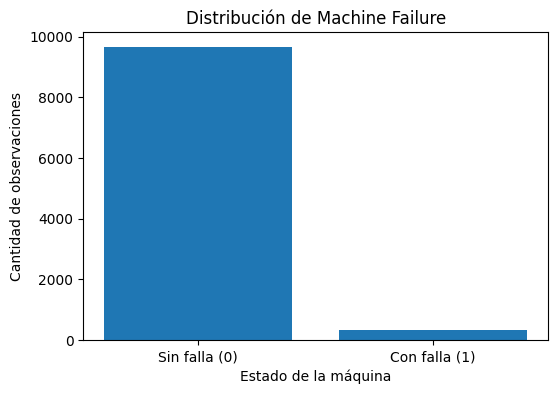

In [14]:
# Contamos cuántos casos corresponden a máquinas sin falla y cuántos corresponden a máquinas con falla.

cantidad_fallas = df_eda["Machine failure"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Sin falla (0)", "Con falla (1)"],
    cantidad_fallas.values
)

plt.title("Distribución de Machine Failure")
plt.xlabel("Estado de la máquina")
plt.ylabel("Cantidad de observaciones")

plt.show()

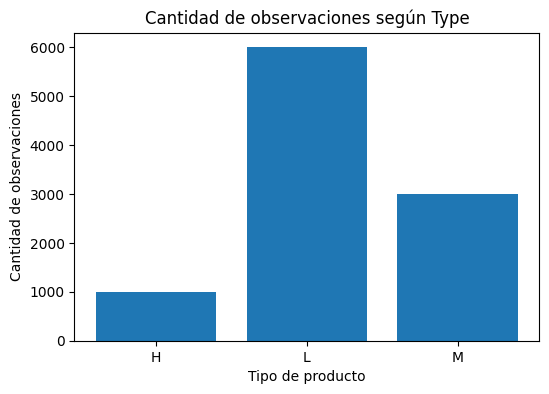

In [15]:
# Contamos cuántas observaciones existen para cada tipo de producto.

cantidad_type = df_eda["Type"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    cantidad_type.index,
    cantidad_type.values
)

plt.title("Cantidad de observaciones según Type")
plt.xlabel("Tipo de producto")
plt.ylabel("Cantidad de observaciones")

plt.show()

Casos con falla y sin falla según Type:


Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


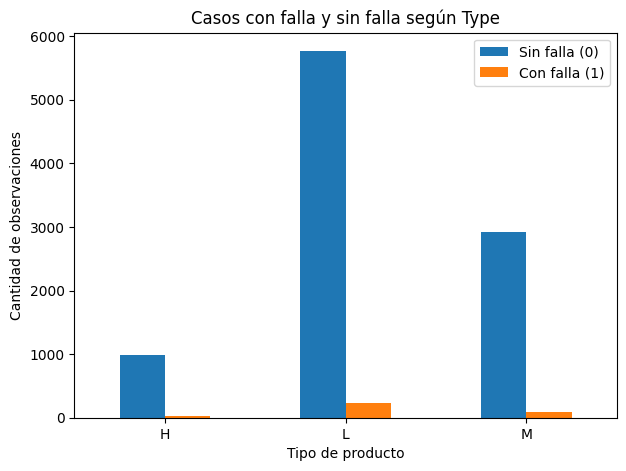

In [16]:
# Contamos los casos con falla y sin falla dentro de cada tipo de producto.

fallas_type = pd.crosstab(
    df_eda["Type"],
    df_eda["Machine failure"]
)

# Mostramos primero los valores en forma de tabla.

print("Casos con falla y sin falla según Type:")
display(fallas_type)

# y creamos el gráfico.

fallas_type.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Casos con falla y sin falla según Type")
plt.xlabel("Tipo de producto")
plt.ylabel("Cantidad de observaciones")
plt.xticks(rotation=0)
plt.legend(["Sin falla (0)", "Con falla (1)"])

plt.show()

Porcentaje de fallas según Type:
Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


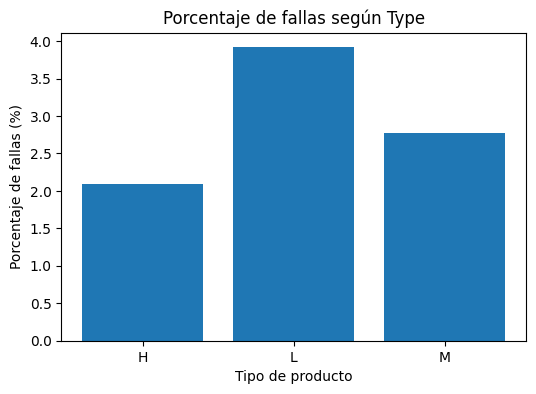

In [17]:
# Calculamos qué porcentaje de las observaciones de cada Type corresponde a una falla.

porcentaje_fallas_type = (
    df_eda.groupby("Type")["Machine failure"].mean() * 100
)

print("Porcentaje de fallas según Type:")
print(porcentaje_fallas_type.round(2))

plt.figure(figsize=(6, 4))

plt.bar(
    porcentaje_fallas_type.index,
    porcentaje_fallas_type.values
)

plt.title("Porcentaje de fallas según Type")
plt.xlabel("Tipo de producto")
plt.ylabel("Porcentaje de fallas (%)")

plt.show()

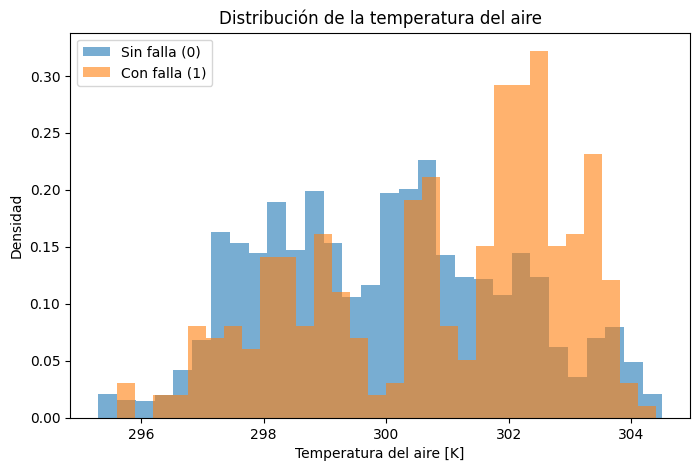

In [18]:
# Separamos los valores de temperatura del aire según si ocurrió o no una falla.

aire_sin_falla = df_eda[
    df_eda["Machine failure"] == 0
]["Air temperature [K]"]

aire_con_falla = df_eda[
    df_eda["Machine failure"] == 1
]["Air temperature [K]"]

# Mostramos las distribuciones.

plt.figure(figsize=(8, 5))

plt.hist(
    aire_sin_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Sin falla (0)"
)

plt.hist(
    aire_con_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Con falla (1)"
)

plt.title("Distribución de la temperatura del aire")
plt.xlabel("Temperatura del aire [K]")
plt.ylabel("Densidad")
plt.legend()

plt.show()

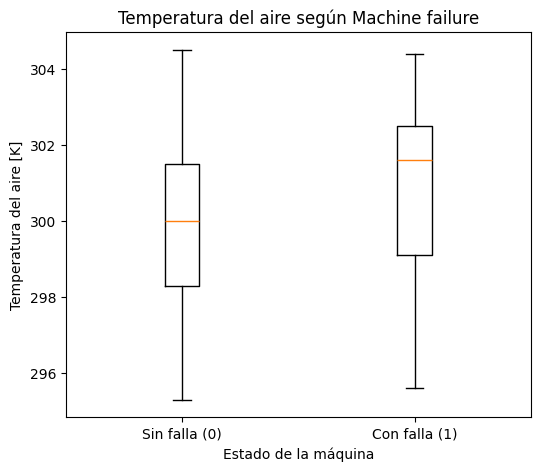

In [19]:
# Utilizamos un boxplot para comparar la temperatura del aire de las máquinas sin falla y con falla.

plt.figure(figsize=(6, 5))

plt.boxplot(
    [
        aire_sin_falla,
        aire_con_falla
    ]
)

plt.xticks(
    [1, 2],
    ["Sin falla (0)", "Con falla (1)"]
)

plt.title("Temperatura del aire según Machine failure")
plt.xlabel("Estado de la máquina")
plt.ylabel("Temperatura del aire [K]")

plt.show()

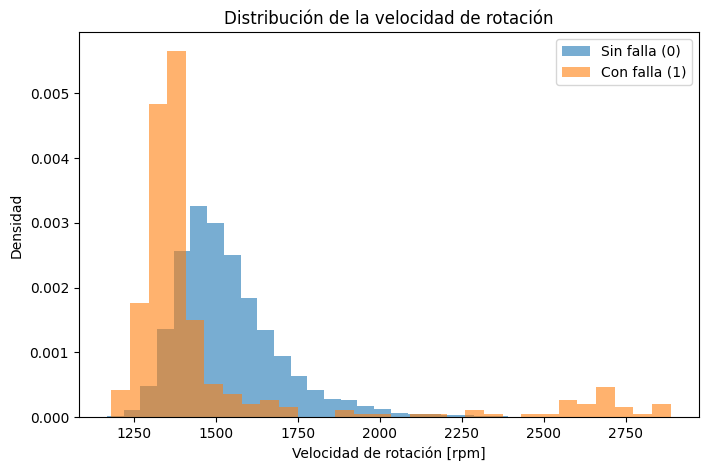

In [20]:
# Separamos los valores de velocidad de rotación según si ocurrió o no una falla.

velocidad_sin_falla = df_eda[
    df_eda["Machine failure"] == 0
]["Rotational speed [rpm]"]

velocidad_con_falla = df_eda[
    df_eda["Machine failure"] == 1
]["Rotational speed [rpm]"]

plt.figure(figsize=(8, 5))

plt.hist(
    velocidad_sin_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Sin falla (0)"
)

plt.hist(
    velocidad_con_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Con falla (1)"
)

plt.title("Distribución de la velocidad de rotación")
plt.xlabel("Velocidad de rotación [rpm]")
plt.ylabel("Densidad")
plt.legend()

plt.show()

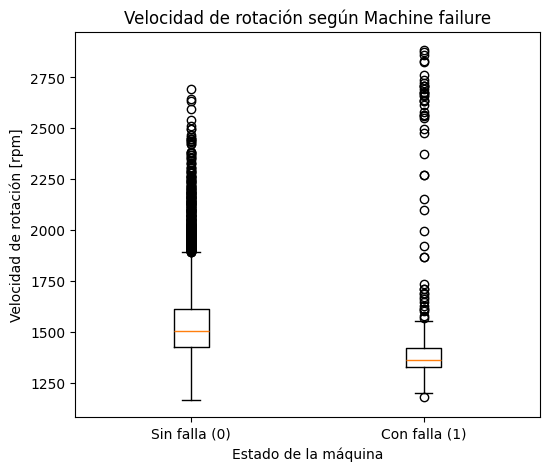

In [21]:
# Comparamos la velocidad de rotación entre máquinas sin falla y con falla.

plt.figure(figsize=(6, 5))

plt.boxplot(
    [
        velocidad_sin_falla,
        velocidad_con_falla
    ]
)

plt.xticks(
    [1, 2],
    ["Sin falla (0)", "Con falla (1)"]
)

plt.title("Velocidad de rotación según Machine failure")
plt.xlabel("Estado de la máquina")
plt.ylabel("Velocidad de rotación [rpm]")

plt.show()

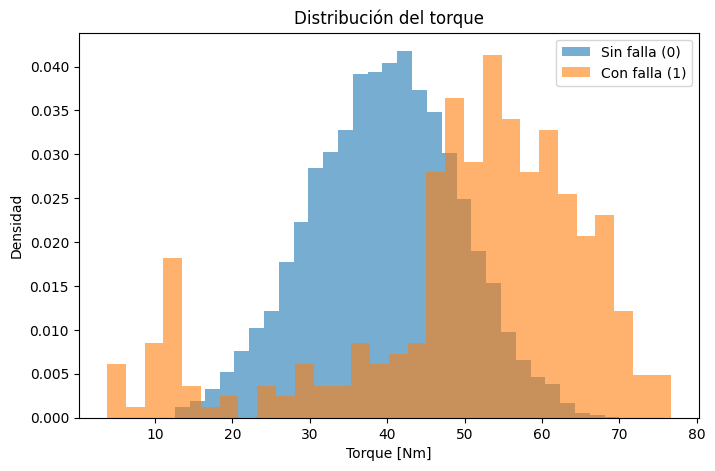

In [22]:
# Separamos los valores de torque según si ocurrió o no una falla.

torque_sin_falla = df_eda[
    df_eda["Machine failure"] == 0
]["Torque [Nm]"]

torque_con_falla = df_eda[
    df_eda["Machine failure"] == 1
]["Torque [Nm]"]

plt.figure(figsize=(8, 5))

plt.hist(
    torque_sin_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Sin falla (0)"
)

plt.hist(
    torque_con_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Con falla (1)"
)

plt.title("Distribución del torque")
plt.xlabel("Torque [Nm]")
plt.ylabel("Densidad")
plt.legend()

plt.show()

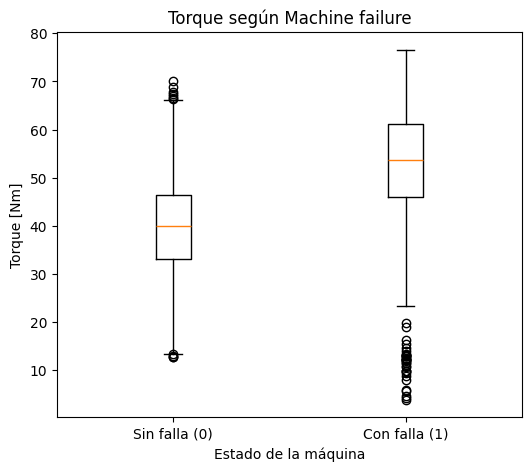

In [24]:
# Comparamos el torque entre máquinas sin falla y con falla.

plt.figure(figsize=(6, 5))

plt.boxplot(
    [
        torque_sin_falla,
        torque_con_falla
    ]
)

plt.xticks(
    [1, 2],
    ["Sin falla (0)", "Con falla (1)"]
)

plt.title("Torque según Machine failure")
plt.xlabel("Estado de la máquina")
plt.ylabel("Torque [Nm]")

plt.show()

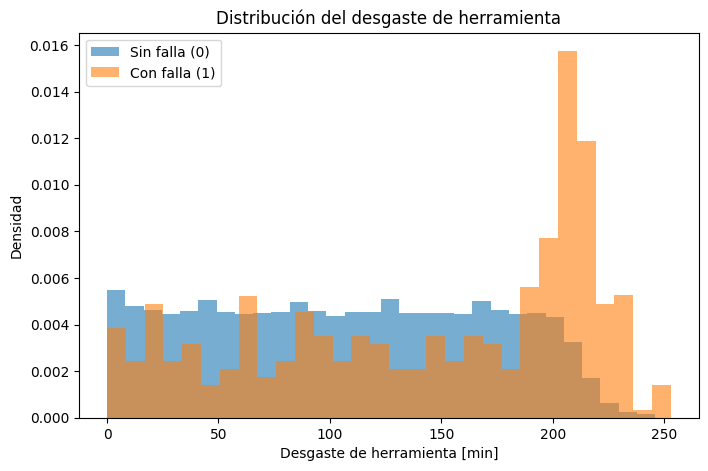

In [25]:
# Separamos los valores de desgaste de herramienta según si ocurrió o no una falla.

desgaste_sin_falla = df_eda[
    df_eda["Machine failure"] == 0
]["Tool wear [min]"]

desgaste_con_falla = df_eda[
    df_eda["Machine failure"] == 1
]["Tool wear [min]"]

plt.figure(figsize=(8, 5))

plt.hist(
    desgaste_sin_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Sin falla (0)"
)

plt.hist(
    desgaste_con_falla,
    bins=30,
    alpha=0.6,
    density=True,
    label="Con falla (1)"
)

plt.title("Distribución del desgaste de herramienta")
plt.xlabel("Desgaste de herramienta [min]")
plt.ylabel("Densidad")
plt.legend()

plt.show()

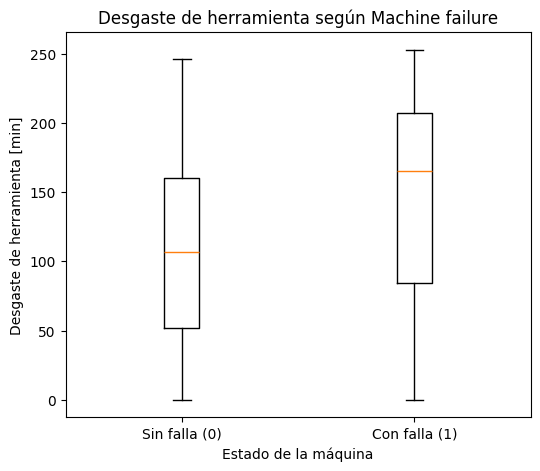

In [26]:
# Comparamos el desgaste de herramienta entre máquinas sin falla y con falla.

plt.figure(figsize=(6, 5))

plt.boxplot(
    [
        desgaste_sin_falla,
        desgaste_con_falla
    ]
)

plt.xticks(
    [1, 2],
    ["Sin falla (0)", "Con falla (1)"]
)

plt.title("Desgaste de herramienta según Machine failure")
plt.xlabel("Estado de la máquina")
plt.ylabel("Desgaste de herramienta [min]")

plt.show()

In [27]:
# Creamos dos tablas auxiliares para utilizar en los gráficos de dispersión.

datos_sin_falla = df_eda[
    df_eda["Machine failure"] == 0
]

datos_con_falla = df_eda[
    df_eda["Machine failure"] == 1
]

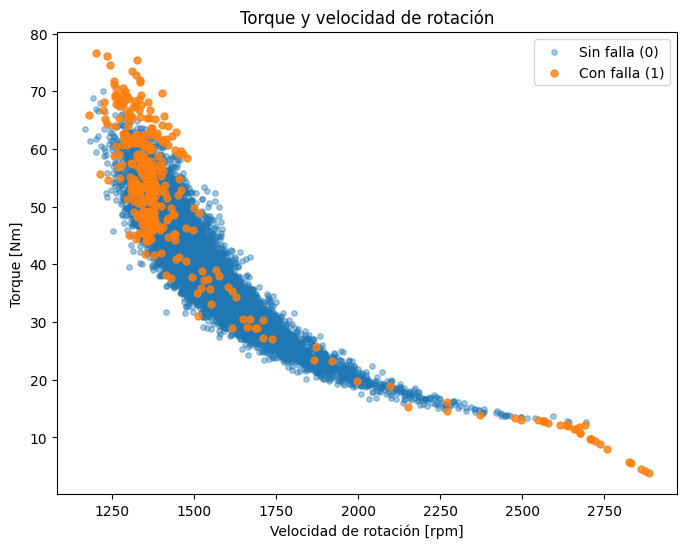

In [28]:
# Analizamos la relación entre velocidad de rotación y torque.

plt.figure(figsize=(8, 6))

plt.scatter(
    datos_sin_falla["Rotational speed [rpm]"],
    datos_sin_falla["Torque [Nm]"],
    alpha=0.4,
    s=15,
    label="Sin falla (0)"
)

plt.scatter(
    datos_con_falla["Rotational speed [rpm]"],
    datos_con_falla["Torque [Nm]"],
    alpha=0.8,
    s=25,
    label="Con falla (1)"
)

plt.title("Torque y velocidad de rotación")
plt.xlabel("Velocidad de rotación [rpm]")
plt.ylabel("Torque [Nm]")
plt.legend()

plt.show()

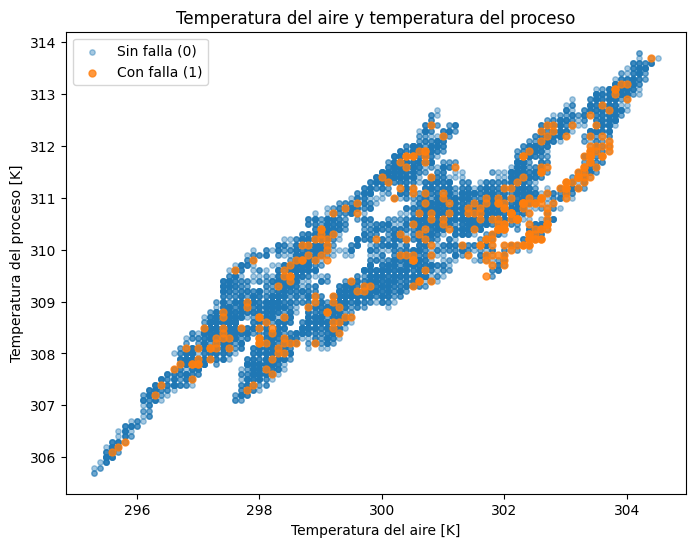

In [29]:
# Analizamos la relación entre la temperatura del aire
# y la temperatura del proceso.

plt.figure(figsize=(8, 6))

plt.scatter(
    datos_sin_falla["Air temperature [K]"],
    datos_sin_falla["Process temperature [K]"],
    alpha=0.4,
    s=15,
    label="Sin falla (0)"
)

plt.scatter(
    datos_con_falla["Air temperature [K]"],
    datos_con_falla["Process temperature [K]"],
    alpha=0.8,
    s=25,
    label="Con falla (1)"
)

plt.title("Temperatura del aire y temperatura del proceso")
plt.xlabel("Temperatura del aire [K]")
plt.ylabel("Temperatura del proceso [K]")
plt.legend()

plt.show()

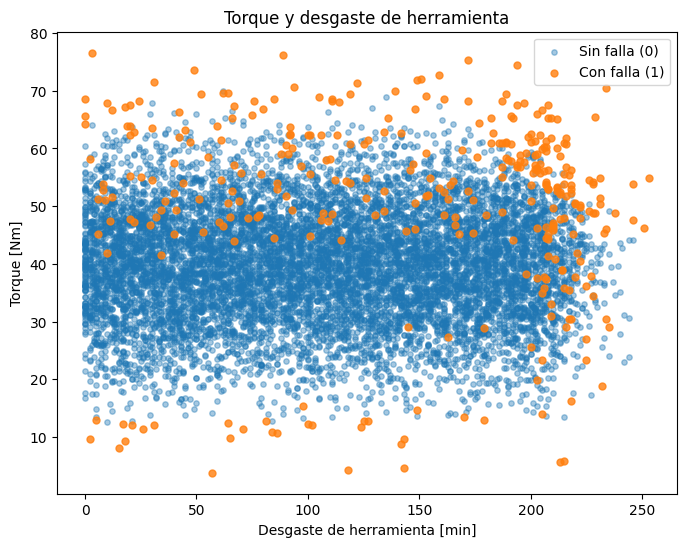

In [30]:
# Analizamos conjuntamente el torque y el desgaste de la herramienta.

plt.figure(figsize=(8, 6))

plt.scatter(
    datos_sin_falla["Tool wear [min]"],
    datos_sin_falla["Torque [Nm]"],
    alpha=0.4,
    s=15,
    label="Sin falla (0)"
)

plt.scatter(
    datos_con_falla["Tool wear [min]"],
    datos_con_falla["Torque [Nm]"],
    alpha=0.8,
    s=25,
    label="Con falla (1)"
)

plt.title("Torque y desgaste de herramienta")
plt.xlabel("Desgaste de herramienta [min]")
plt.ylabel("Torque [Nm]")
plt.legend()

plt.show()

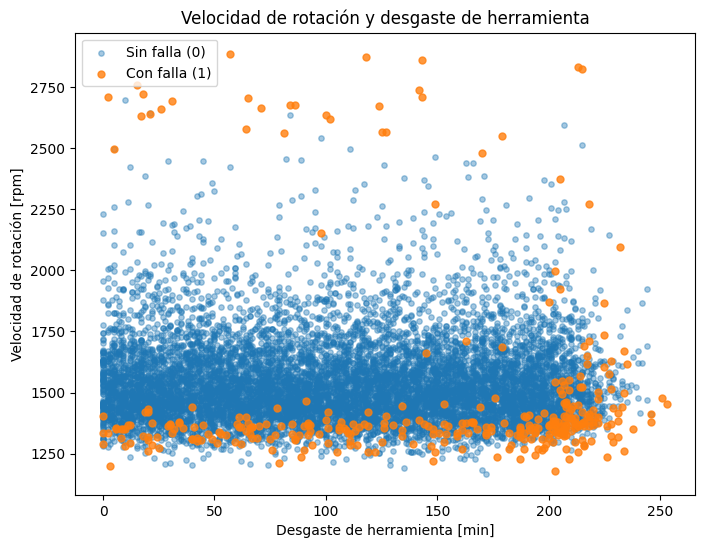

In [31]:
# Analizamos conjuntamente la velocidad de rotación y el desgaste de la herramienta.

plt.figure(figsize=(8, 6))

plt.scatter(
    datos_sin_falla["Tool wear [min]"],
    datos_sin_falla["Rotational speed [rpm]"],
    alpha=0.4,
    s=15,
    label="Sin falla (0)"
)

plt.scatter(
    datos_con_falla["Tool wear [min]"],
    datos_con_falla["Rotational speed [rpm]"],
    alpha=0.8,
    s=25,
    label="Con falla (1)"
)

plt.title("Velocidad de rotación y desgaste de herramienta")
plt.xlabel("Desgaste de herramienta [min]")
plt.ylabel("Velocidad de rotación [rpm]")
plt.legend()

plt.show()

In [32]:
# Seleccionamos únicamente las variables numéricas.

variables_numericas = df_eda[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Machine failure"
    ]
]

# Calculamos la correlación entre todas las variables.

correlaciones = variables_numericas.corr()

print("Matriz de correlación:")
display(correlaciones.round(2))

Matriz de correlación:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.00,0.88,0.02,-0.01,0.01,0.08
Process temperature [K],0.88,1.00,0.02,-0.01,0.01,0.04
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00,-0.04
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00,0.19
Tool wear [min],0.01,0.01,0.00,-0.00,1.00,0.11
Machine failure,0.08,0.04,-0.04,0.19,0.11,1.00


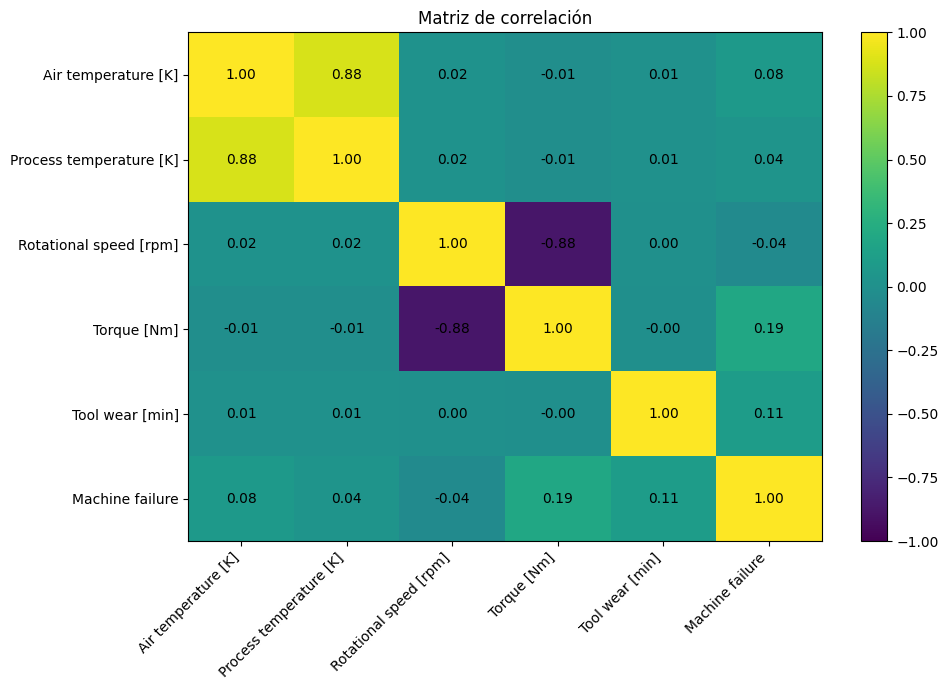

In [33]:
# Representamos gráficamente la matriz de correlación.

plt.figure(figsize=(10, 7))

imagen = plt.imshow(
    correlaciones,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(imagen)

plt.xticks(
    range(len(correlaciones.columns)),
    correlaciones.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlaciones.index)),
    correlaciones.index
)

# Escribimos dentro de cada casilla
# el valor correspondiente de correlación.

for fila in range(len(correlaciones.index)):
    for columna in range(len(correlaciones.columns)):
        valor = correlaciones.iloc[fila, columna]

        plt.text(
            columna,
            fila,
            f"{valor:.2f}",
            ha="center",
            va="center"
        )

plt.title("Matriz de correlación")
plt.tight_layout()

plt.show()

In [34]:
# Calculamos el promedio de cada variable numérica para las máquinas sin falla y con falla.

promedios_por_falla = df_eda.groupby("Machine failure")[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
].mean()

promedios_por_falla = promedios_por_falla.round(2)

print("Valores promedio según Machine failure:")
display(promedios_por_falla)

Valores promedio según Machine failure:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.97,310.00,1540.26,39.63,106.69
1,300.89,310.29,1496.49,50.17,143.78


**Interpretación del análisis exploratorio**

El análisis exploratorio muestra que las fallas representan una proporción muy pequeña del total de observaciones, confirmando el fuerte desbalance de la variable "Machine failure".

Al analizar Type, el tipo L presenta el mayor porcentaje de fallas (3,92 %), seguido por M (2,77 %) y H (2,09 %).

Entre las variables numéricas se observan diferencias entre las máquinas con falla y sin falla. Los casos con falla presentan, en promedio, un torque mayor (50,17 Nm frente a 39,63 Nm), un mayor desgaste de herramienta (143,78 min frente a 106,69 min) y una velocidad de rotación algo menor (1496,49 rpm frente a 1540,26 rpm). Las diferencias en las temperaturas son menores.

La matriz de correlación también muestra una relación positiva de Machine failure con Torque y Tool wear. Además, existe una fuerte relación positiva entre Air temperature y Process temperature, y una fuerte relación negativa entre Rotational speed y Torque.

Los gráficos muestran que existe bastante superposición entre los casos con falla y sin falla, por lo que ninguna de las variables analizadas permite separar por sí sola ambos grupos de manera clara. Esto justifica utilizar modelos de Machine Learning que puedan analizar varias variables de forma conjunta para realizar la clasificación.

### **4 - Codificación y preparación de los datos**

In [35]:
# Observamos los valores que contiene la variable Type.
# Esta variable representa el tipo de producto y está expresada con letras.

print("Valores de la variable Type:")
print(df_modelo["Type"].value_counts())

Valores de la variable Type:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


In [36]:
# La variable Type es categórica y los modelos necesitan trabajar con valores numéricos. Por lo tanto utilizamos "One-Hot Encoding" para transformar las categorías L, M y H en columnas independientes formadas por valores 0 y 1.

df_modelo = pd.get_dummies(
    df_modelo,
    columns=["Type"],
    dtype=int
)

# Mostramos las primeras filas para comprobar el resultado.
print("Base de datos después de codificar Type:")
display(df_modelo.head())

Base de datos después de codificar Type:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,0,1,0
2,298.1,308.5,1498,49.4,5,0,0,1,0
3,298.2,308.6,1433,39.5,7,0,0,1,0
4,298.2,308.7,1408,40.0,9,0,0,1,0


In [37]:
# Separamos las variables que utilizará el modelo para realizar las predicciones.
# definimos X, que contiene las variables predictoras.

X = df_modelo.drop(columns=["Machine failure"])

# definimos y que contiene la variable que queremos predecir:
# 0 = sin falla
# 1 = con falla

y = df_modelo["Machine failure"]

# Mostramos las variables que quedaron dentro de X.
print("Variables predictoras:")
print(X.columns)

# Mostramos las dimensiones de X e y.
print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Variables predictoras:
Index(['Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H',
       'Type_L', 'Type_M'],
      dtype='object')

Dimensiones de X: (10000, 8)
Dimensiones de y: (10000,)


### **5 - División de los datos en entrenamiento y prueba**

In [38]:
# Importamos la herramienta train_test_split que permite dividir los datos en un conjunto de entrenamiento y un conjunto de prueba.
from sklearn.model_selection import train_test_split

# Dividimos los datos:
# El 80 % se utilizará para entrenar los modelos y el 20 % se utilizará para evaluarlo.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [39]:
# Mostramos la cantidad de observaciones que quedó en cada conjunto.
print("Cantidad de datos para entrenamiento:")
print(X_train.shape)

print("Cantidad de datos para prueba:")
print(X_test.shape)

Cantidad de datos para entrenamiento:
(8000, 8)
Cantidad de datos para prueba:
(2000, 8)


In [40]:
# Comprobamos cuántos casos de falla y no falla quedaron en cada conjunto.

print("Entrenamiento")
print("Sin falla (0):", (y_train == 0).sum())
print("Con falla (1):", (y_train == 1).sum())

print("Prueba")
print("Sin falla (0):", (y_test == 0).sum())
print("Con falla (1):", (y_test == 1).sum())

Entrenamiento
Sin falla (0): 7729
Con falla (1): 271
Prueba
Sin falla (0): 1932
Con falla (1): 68


In [41]:
# También mostramos los porcentajes para comprobar que el desbalance se mantuvo de forma similar.

print("Porcentaje de clases en entrenamiento:")
print("Sin falla (0):", round((y_train == 0).mean() * 100, 2), "%")
print("Con falla (1):", round((y_train == 1).mean() * 100, 2), "%")

print("Porcentaje de clases en prueba:")
print("Sin falla (0):", round((y_test == 0).mean() * 100, 2), "%")
print("Con falla (1):", round((y_test == 1).mean() * 100, 2), "%")

Porcentaje de clases en entrenamiento:
Sin falla (0): 96.61 %
Con falla (1): 3.39 %
Porcentaje de clases en prueba:
Sin falla (0): 96.6 %
Con falla (1): 3.4 %


### **6 - Selección de la métrica y entrenamiento de los modelos**

In [42]:
# Estandarizamos las variables para los modelos que trabajan mejor cuando las variables se encuentran en una escala comparable.

# El escalador aprende la media y la desviación estándar, utilizando únicamente los datos de entrenamiento.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_escalado = scaler.fit_transform(X_train)

# Para los datos de prueba utilizamos exactamennto la misma transformación aprendida con los datos de entrenamiento.


X_test_escalado = scaler.transform(X_test)

print("Escalado de los datos completado")
print("Datos de entrenamiento:", X_train_escalado.shape)
print("Datos de prueba:", X_test_escalado.shape)

Escalado de los datos completado
Datos de entrenamiento: (8000, 8)
Datos de prueba: (2000, 8)


In [43]:
# REGRESIÓN LOGÍSTICA

# Creamos el modelo de Regresión Logística.

# class_weight="balanced" tiene en cuenta que existen muchos menos casos con falla que casos sin falla.

modelo_logistica = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Entrenamos el modelo utilizando los datos de entrenamiento escalados.
modelo_logistica.fit(X_train_escalado, y_train)

# Realizamos las predicciones sobre los datos de prueba.
pred_logistica = modelo_logistica.predict(X_test_escalado)

print("Regresión Logística entrenada correctamente")
print("Predicciones realizadas:", len(pred_logistica))

Regresión Logística entrenada correctamente
Predicciones realizadas: 2000


In [44]:
# SVC


# # Creamos el modelo SVC.
# Utilizamos nuevamente class_weight="balanced" debido al desbalance

modelo_svc = SVC(
    class_weight="balanced"
)

# Entrenamos el modelo utilizando los datos escalados.
modelo_svc.fit(X_train_escalado, y_train)

# Realizamos las predicciones sobre los datos de prueba.
pred_svc = modelo_svc.predict(X_test_escalado)

print("SVC entrenado correctamente")
print("Predicciones realizadas:", len(pred_svc))

SVC entrenado correctamente
Predicciones realizadas: 2000


In [45]:
# ARBOL DE DECISIÓN

# Creamos el modelo de Árbol de Decisión.
# Los árboles no necesitan trabajar con las variables escaladas, ya que comparan cada variable consigo misma

modelo_arbol = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# Entrenamos el modelo utilizando los datos originales.
modelo_arbol.fit(X_train, y_train)

# Realizamos las predicciones sobre los datos de prueba.
pred_arbol = modelo_arbol.predict(X_test)

print("Árbol de Decisión entrenado correctamente")
print("Predicciones realizadas:", len(pred_arbol))

Árbol de Decisión entrenado correctamente
Predicciones realizadas: 2000


In [46]:
# RANDOM FOREST

# Creamos el modelo Random Forest donde combinamos varios árboles de decisión.

modelo_random_forest = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

# Entrenamos el modelo utilizando los datos originales.
modelo_random_forest.fit(X_train, y_train)

# Realizamos las predicciones sobre los datos de prueba.
pred_random_forest = modelo_random_forest.predict(X_test)

print("Random Forest entrenado correctamente")
print("Predicciones realizadas:", len(pred_random_forest))

Random Forest entrenado correctamente
Predicciones realizadas: 2000


### **7 - Evaluación y comparación de los modelos**

In [47]:
# Evaluación de regresión logística

## Comparamos las predicciones de la Regresión Logística con los valores reales del conjunto de prueba.

accuracy_logistica = accuracy_score(y_test, pred_logistica)      # Calcula el porcentaje total de predicciones correctas
precision_logistica = precision_score(y_test, pred_logistica)    # Calcula cuántas predicciones de falla fueron realmente fallas
recall_logistica = recall_score(y_test, pred_logistica)          # Calcula cuántas fallas reales logró detectar el modelo
f1_logistica = f1_score(y_test, pred_logistica)                  # Combina Precision y Recall en una sola métrica

print("Regresión Logística")
print("Accuracy:", round(accuracy_logistica, 4))
print("Precision:", round(precision_logistica, 4))
print("Recall:", round(recall_logistica, 4))
print("F1-score:", round(f1_logistica, 4))

Regresión Logística
Accuracy: 0.825
Precision: 0.1421
Recall: 0.8235
F1-score: 0.2424


In [48]:
## Evaluación SVC

# Idem al anterior pero con modelo SVC.

accuracy_svc = accuracy_score(y_test, pred_svc)
precision_svc = precision_score(y_test, pred_svc)
recall_svc = recall_score(y_test, pred_svc)
f1_svc = f1_score(y_test, pred_svc)

print("SVC")
print("Accuracy:", round(accuracy_svc, 4))
print("Precision:", round(precision_svc, 4))
print("Recall:", round(recall_svc, 4))
print("F1-score:", round(f1_svc, 4))

SVC
Accuracy: 0.917
Precision: 0.2793
Recall: 0.9118
F1-score: 0.4276


In [49]:
# Evaluación Árbol de Decisión

# Idem al anterior pero con árbol de decisión

accuracy_arbol = accuracy_score(y_test, pred_arbol)
precision_arbol = precision_score(y_test, pred_arbol)
recall_arbol = recall_score(y_test, pred_arbol)
f1_arbol = f1_score(y_test, pred_arbol)

print("Árbol de Decisión")
print("Accuracy:", round(accuracy_arbol, 4))
print("Precision:", round(precision_arbol, 4))
print("Recall:", round(recall_arbol, 4))
print("F1-score:", round(f1_arbol, 4))

Árbol de Decisión
Accuracy: 0.978
Precision: 0.7069
Recall: 0.6029
F1-score: 0.6508


In [50]:
#Evaluación Random forest

# Idem al anterior pero con Random Forest

accuracy_random_forest = accuracy_score(y_test, pred_random_forest)
precision_random_forest = precision_score(y_test, pred_random_forest)
recall_random_forest = recall_score(y_test, pred_random_forest)
f1_random_forest = f1_score(y_test, pred_random_forest)

print("Random Forest")
print("Accuracy:", round(accuracy_random_forest, 4))
print("Precision:", round(precision_random_forest, 4))
print("Recall:", round(recall_random_forest, 4))
print("F1-score:", round(f1_random_forest, 4))

Random Forest
Accuracy: 0.979
Precision: 0.9643
Recall: 0.3971
F1-score: 0.5625


In [51]:
# Resultados de los cuatro modelos en una misma tabla para compararlos.

resultados = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "SVC",
        "Árbol de Decisión",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistica,
        accuracy_svc,
        accuracy_arbol,
        accuracy_random_forest
    ],
    "Precision": [
        precision_logistica,
        precision_svc,
        precision_arbol,
        precision_random_forest
    ],
    "Recall": [
        recall_logistica,
        recall_svc,
        recall_arbol,
        recall_random_forest
    ],
    "F1-score": [
        f1_logistica,
        f1_svc,
        f1_arbol,
        f1_random_forest
    ]
})

# Redondeamos los valores para facilitar la lectura.
resultados = resultados.round(4)

print("Comparación de los modelos:")
display(resultados)

Comparación de los modelos:


,Modelo,Accuracy,Precision,Recall,F1-score
0,Regresión Logística,0.825,0.1421,0.8235,0.2424
1,SVC,0.917,0.2793,0.9118,0.4276
2,Árbol de Decisión,0.978,0.7069,0.6029,0.6508
3,Random Forest,0.979,0.9643,0.3971,0.5625


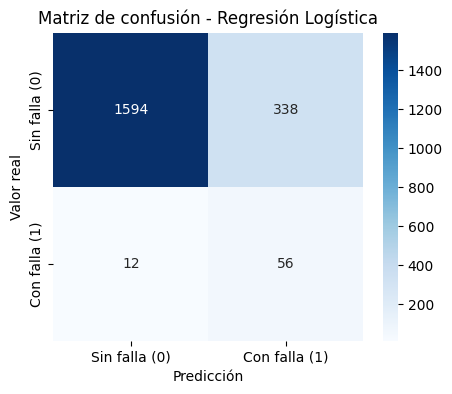

In [52]:
# Cálculo de la matriz de confusión para la regresión logistica.

matriz_logistica = confusion_matrix(y_test, pred_logistica)

# La representamos gráficamente.
plt.figure(figsize=(5, 4))

sns.heatmap(
    matriz_logistica,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matriz de confusión - Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])
plt.yticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])

plt.show()

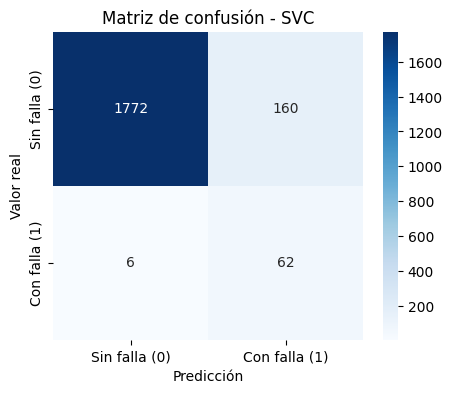

In [53]:
#Idem pero para svc

matriz_svc = confusion_matrix(y_test, pred_svc)

plt.figure(figsize=(5, 4))

sns.heatmap(
    matriz_svc,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matriz de confusión - SVC")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])
plt.yticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])

plt.show()

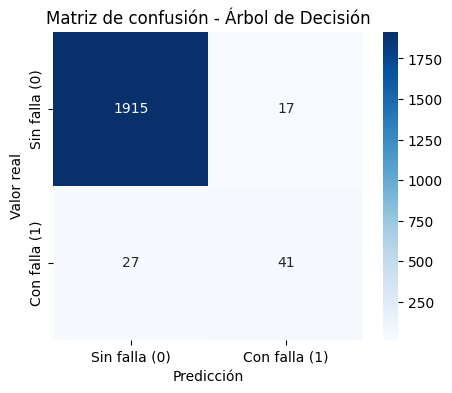

In [54]:
#Idem pero para arbol de decisión

matriz_arbol = confusion_matrix(y_test, pred_arbol)

plt.figure(figsize=(5, 4))

sns.heatmap(
    matriz_arbol,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matriz de confusión - Árbol de Decisión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])
plt.yticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])

plt.show()

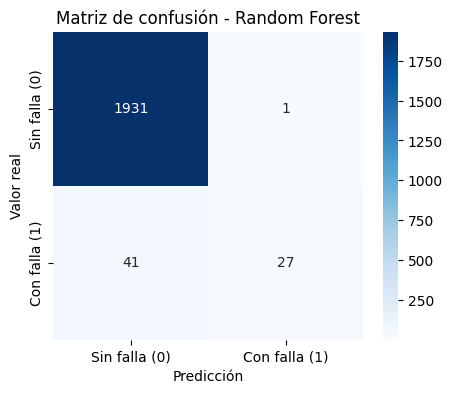

In [55]:
#Idem para random forest

matriz_random_forest = confusion_matrix(y_test, pred_random_forest)

plt.figure(figsize=(5, 4))

sns.heatmap(
    matriz_random_forest,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])
plt.yticks([0.5, 1.5], ["Sin falla (0)", "Con falla (1)"])

plt.show()

### **Comparación de modelos**

In [56]:
# Buscamos qué modelo obtuvo el valor más alto de F1-score.
mejor_modelo = resultados.loc[resultados["F1-score"].idxmax()]

# Mostramos el modelo y su F1-score.
print("Modelo con mejor F1-score:")
print(mejor_modelo["Modelo"])

print("F1-score:")
print(mejor_modelo["F1-score"])

Modelo con mejor F1-score:
Árbol de Decisión
F1-score:
0.6508


In [57]:
# Buscamos qué modelo obtuvo el valor más alto en cada métrica.

mejor_accuracy = resultados.loc[resultados["Accuracy"].idxmax()]
mejor_precision = resultados.loc[resultados["Precision"].idxmax()]
mejor_recall = resultados.loc[resultados["Recall"].idxmax()]
mejor_f1 = resultados.loc[resultados["F1-score"].idxmax()]

print("Mejor Accuracy:", mejor_accuracy["Modelo"], "-", mejor_accuracy["Accuracy"])
print("Mejor Precision:", mejor_precision["Modelo"], "-", mejor_precision["Precision"])
print("Mejor Recall:", mejor_recall["Modelo"], "-", mejor_recall["Recall"])
print("Mejor F1-score:", mejor_f1["Modelo"], "-", mejor_f1["F1-score"])

Mejor Accuracy: Random Forest - 0.979
Mejor Precision: Random Forest - 0.9643
Mejor Recall: SVC - 0.9118
Mejor F1-score: Árbol de Decisión - 0.6508


In [59]:
# 7 - Evaluación y comparación de los modelos según la jerarquía declarada

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Diccionario para almacenar los resultados de forma estructurada
evaluacion_modelos = []

modelos_dict = {
    "Regresión Logística": (modelo_logistica, X_test_escalado),
    "SVC": (modelo_svc, X_test_escalado),
    "Árbol de Decisión": (modelo_arbol, X_test),
    "Random Forest": (modelo_random_forest, X_test)
}

print("--- Evaluando modelos según jerarquía de métricas ---")

for nombre, (modelo, x_datos) in modelos_dict.items():
    # Predicciones duras (para Recall, Precision, F1)
    y_pred = modelo.predict(x_datos)

    # Obtenemos las puntuaciones continuas para ROC-AUC y PR-AUC
    # Si el modelo tiene predict_proba, tomamos la probabilidad de la clase positiva (1)
    if hasattr(modelo, "predict_proba"):
        y_score = modelo.predict_proba(x_datos)[:, 1]
    # De lo contrario (como en SVC sin probability=True), usamos la función de decisión
    else:
        y_score = modelo.decision_function(x_datos)

    # Cálculo de métricas
    acc = accuracy_score(y_test, y_pred)             # Informativa (descartada para decisión)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Usamos y_score que contiene la salida continua correcta del modelo
    roc_auc = roc_auc_score(y_test, y_score)
    pr_auc = average_precision_score(y_test, y_score)

    evaluacion_modelos.append({
        "Modelo": nombre,
        "Recall (1º Prioridad)": rec,
        "PR-AUC (2º Prioridad)": pr_auc,
        "F1-score (2º Prioridad)": f1,
        "ROC-AUC (Control)": roc_auc,
        "Precision": prec,
        "Accuracy (Descartado)": acc
    })

# Convertimos a DataFrame y ordenamos coherentemente
resultados_jerarquicos = pd.DataFrame(evaluacion_modelos)
resultados_jerarquicos = resultados_jerarquicos.round(4)

print("\nTabla Comparativa de Desempeño:")
display(resultados_jerarquicos)

--- Evaluando modelos según jerarquía de métricas ---

Tabla Comparativa de Desempeño:


,Modelo,Recall (1º Prioridad),PR-AUC (2º Prioridad),F1-score (2º Prioridad),ROC-AUC (Control),Precision,Accuracy (Descartado)
0,Regresión Logística,0.8235,0.3817,0.2424,0.9069,0.1421,0.825
1,SVC,0.9118,0.6023,0.4276,0.9610,0.2793,0.917
2,Árbol de Decisión,0.6029,0.4397,0.6508,0.7971,0.7069,0.978
3,Random Forest,0.3971,0.7626,0.5625,0.9635,0.9643,0.979


# **8- Interpretabilidad con SHAP**

Calculando valores SHAP para interpretar el Árbol de Decisión...


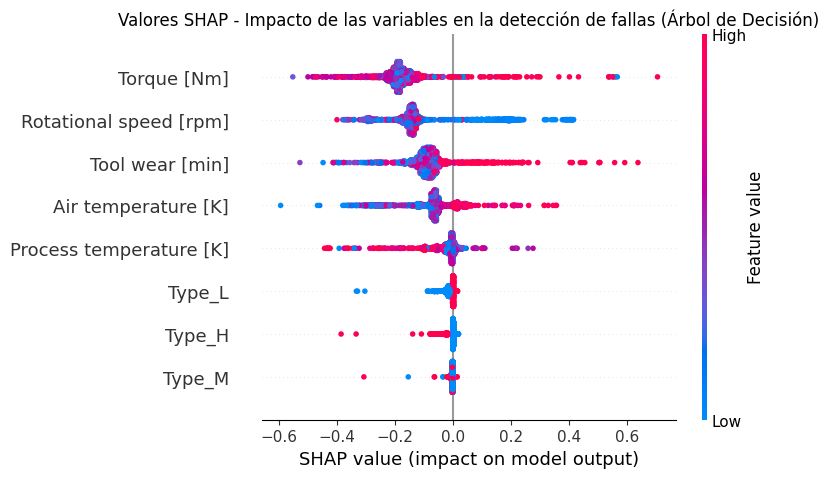

In [63]:
# 8 - Interpretabilidad del modelo con valores SHAP

import shap

print("Calculando valores SHAP para interpretar el Árbol de Decisión...")

# Inicializamos el TreeExplainer utilizando el modelo de Árbol de Decisión
explainer = shap.TreeExplainer(modelo_arbol)

# Calculamos los valores SHAP utilizando X_test (recuerda que el Árbol de Decisión
# fue entrenado con los datos originales, sin escalar)
shap_values = explainer.shap_values(X_test)

# Generamos el gráfico de resumen (Summary Plot)
plt.figure(figsize=(10, 6))

# Adaptación dinámica de las dimensiones de shap_values
if isinstance(shap_values, list):
    # Si es una lista de arrays por clase (versión clásica)
    valores_a_graficar = shap_values[1]
elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
    # Si es un array 3D: (muestras, variables, clases), seleccionamos la clase 1
    valores_a_graficar = shap_values[:, :, 1]
else:
    # Si ya viene en formato 2D directo para la clase positiva
    valores_a_graficar = shap_values

# Graficamos con los valores adaptados
shap.summary_plot(valores_a_graficar, X_test, plot_type="dot", show=False)

plt.title("Valores SHAP - Impacto de las variables en la detección de fallas (Árbol de Decisión)", fontsize=12)
plt.show()

Calculando valores SHAP para interpretar el modelo Random Forest...


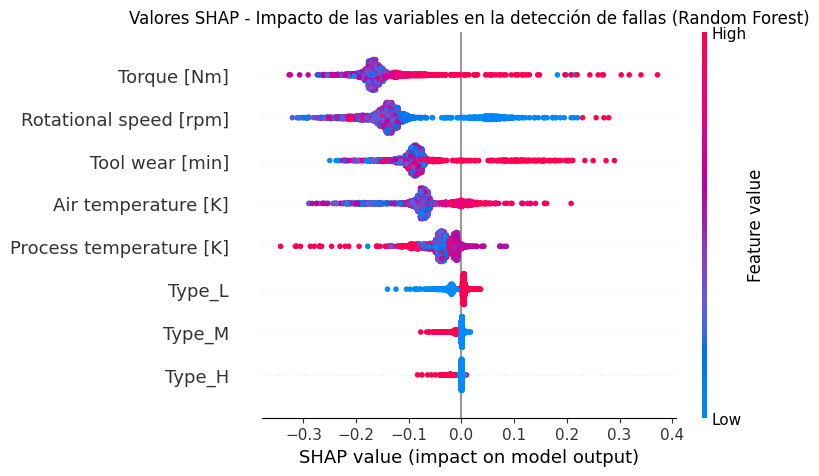

In [64]:
# 8 - Interpretabilidad del modelo con valores SHAP

print("Calculando valores SHAP para interpretar el modelo Random Forest...")

# Inicializamos el TreeExplainer utilizando el modelo Random Forest entrenado
explainer = shap.TreeExplainer(modelo_random_forest)

# Calculamos los valores SHAP utilizando los datos de prueba (X_test)
shap_values = explainer.shap_values(X_test)

# Generamos el gráfico de resumen (Summary Plot)
plt.figure(figsize=(10, 6))

# Adaptación dinámica de las dimensiones de shap_values
if isinstance(shap_values, list):
    # Si es una lista de arrays por clase (versión clásica)
    valores_a_graficar = shap_values[1]
elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
    # Si es un array 3D: (muestras, variables, clases), seleccionamos la clase 1
    valores_a_graficar = shap_values[:, :, 1]
else:
    # Si ya viene en formato 2D directo para la clase positiva
    valores_a_graficar = shap_values

# Graficamos con los valores adaptados
shap.summary_plot(valores_a_graficar, X_test, plot_type="dot", show=False)

plt.title("Valores SHAP - Impacto de las variables en la detección de fallas (Random Forest)", fontsize=12)
plt.show()